In [1]:
# Load the basic and TF-IDF ingredient features for K-Means clustering.
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_basic = pd.read_csv("ingredients_basic.csv")

X_tfidf = load_npz("ingredients_tfidf.npz")

print("Basic Features:", X_basic.shape)
print("TF-IDF Features:", X_tfidf.shape)


Basic Features: (2724, 11)
TF-IDF Features: (2724, 7316)


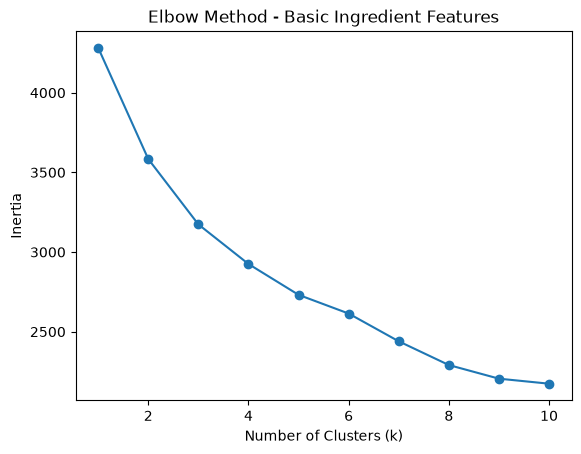

In [2]:
# Apply the Elbow Method to find a suitable number of clusters using basic ingredient features.
inertia_basic = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_basic)
    inertia_basic.append(km.inertia_)

plt.plot(range(1, 11), inertia_basic, marker='o')
plt.title("Elbow Method - Basic Ingredient Features")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.show()


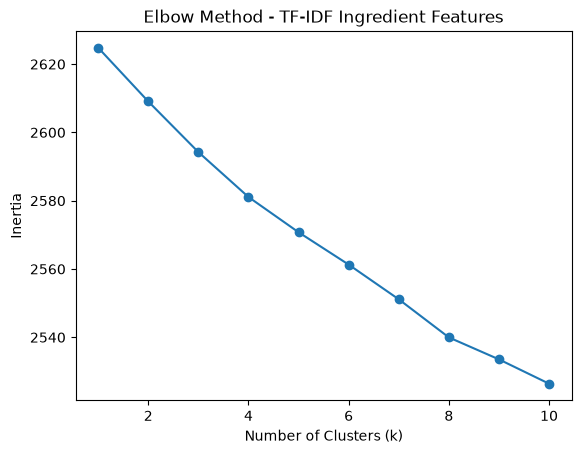

In [3]:
# Apply the Elbow Method using TF-IDF ingredient features.
inertia_tfidf = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_tfidf)
    inertia_tfidf.append(km.inertia_)

plt.plot(range(1, 11), inertia_tfidf, marker='o')
plt.title("Elbow Method - TF-IDF Ingredient Features")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.show()


In [4]:
# Calculate Silhouette Scores for K-Means using the 11 basic ingredient features.
scores_basic = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_basic)

    score = silhouette_score(X_basic, labels, sample_size=500, random_state=42)

    scores_basic.append(score)

    print("k =", k, "Silhouette Score =", round(score, 3))


k = 2 Silhouette Score = 0.179
k = 3 Silhouette Score = 0.184
k = 4 Silhouette Score = 0.178
k = 5 Silhouette Score = 0.195
k = 6 Silhouette Score = 0.189
k = 7 Silhouette Score = 0.219
k = 8 Silhouette Score = 0.228
k = 9 Silhouette Score = 0.237
k = 10 Silhouette Score = 0.225


In [5]:
# Calculate Silhouette Scores for K-Means using TF-IDF ingredient features.
scores_tfidf = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_tfidf)

    score = silhouette_score(X_tfidf, labels, sample_size=500, random_state=42)

    scores_tfidf.append(score)

    print("k =", k, "Silhouette Score =", round(score, 3))


k = 2 Silhouette Score = 0.004
k = 3 Silhouette Score = 0.004
k = 4 Silhouette Score = 0.005
k = 5 Silhouette Score = 0.006
k = 6 Silhouette Score = 0.007
k = 7 Silhouette Score = 0.008
k = 8 Silhouette Score = 0.009
k = 9 Silhouette Score = 0.01
k = 10 Silhouette Score = 0.01


**Why is the TF-IDF silhouette score so low?** The TF-IDF matrix has 7,316 mostly empty columns. In such a
space all products look almost equally far apart (the *curse of dimensionality*), so the silhouette score stays
near 0 regardless of how good the groups are. To compare fairly, TF-IDF is first reduced to 50 components with
**TruncatedSVD**, which combines ingredients that tend to appear together.

Reduced TF-IDF Features: (2724, 50)
Information kept by 50 components: 0.177
k = 2 Silhouette Score = 0.035
k = 3 Silhouette Score = 0.04
k = 4 Silhouette Score = 0.044
k = 5 Silhouette Score = 0.049
k = 6 Silhouette Score = 0.052
k = 7 Silhouette Score = 0.055
k = 8 Silhouette Score = 0.061
k = 9 Silhouette Score = 0.066
k = 10 Silhouette Score = 0.07
k = 11 Silhouette Score = 0.077
k = 12 Silhouette Score = 0.078


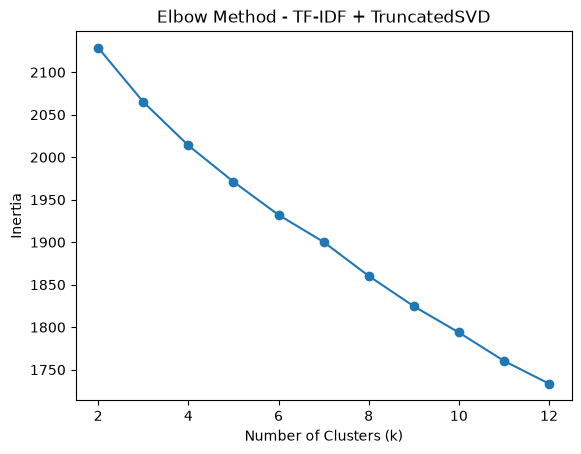

In [6]:
# Reduce TF-IDF to 50 components with TruncatedSVD, then repeat the elbow method and silhouette scores.
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline

svd = TruncatedSVD(n_components=50, random_state=42)
lsa = make_pipeline(svd, Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf)
print("Reduced TF-IDF Features:", X_lsa.shape)
print("Information kept by 50 components:", round(svd.explained_variance_ratio_.sum(), 3))

inertia_lsa, scores_lsa = [], []
for k in range(2, 13):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_lsa)
    inertia_lsa.append(km.inertia_)
    scores_lsa.append(silhouette_score(X_lsa, labels, sample_size=1000, random_state=42))
    print("k =", k, "Silhouette Score =", round(scores_lsa[-1], 3))

plt.plot(range(2, 13), inertia_lsa, marker='o')
plt.title("Elbow Method - TF-IDF + TruncatedSVD")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.show()

In [7]:
# Silhouette scores from different feature spaces cannot be compared directly, so also compare what the
# clusters contain: the share of the most common product category in each cluster (higher = clearer groups).
df = pd.read_csv("skincare_clean.csv")
k = 10
basic_km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_basic)
lsa_km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_lsa)

for name, labels in [("Basic features", basic_km.labels_), ("TF-IDF + SVD", lsa_km.labels_)]:
    mix = pd.crosstab(labels, df["category"])
    purity = (mix.max(axis=1) / mix.sum(axis=1) * 100).round(0).astype(int)
    print(name, "- largest category share per cluster (%):", purity.tolist())

Basic features - largest category share per cluster (%): [24, 21, 29, 26, 28, 22, 39, 51, 31, 28]
TF-IDF + SVD - largest category share per cluster (%): [78, 33, 62, 31, 34, 29, 39, 26, 34, 33]


In [8]:
# Apply K-Means with 10 clusters on TF-IDF + SVD and count products in each cluster.
# TF-IDF + SVD forms recognisable product groups (e.g. sunscreens, foaming cleansers, ceramide products),
# while basic-feature clusters mix product types. k = 10: the elbow curve flattens around 8-10.
final_kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)

cluster_labels = final_kmeans.fit_predict(X_lsa)

print("Products in Each Cluster:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Products in Each Cluster:
0    201
1    455
2    186
3    613
4    203
5    245
6     96
7    339
8     73
9    313
Name: count, dtype: int64


In [9]:
# Calculate the average ingredient feature values for each cluster.
cluster_features = X_basic.copy()
cluster_features["Cluster"] = cluster_labels
cluster_summary = cluster_features.groupby("Cluster").mean().round(2)
display(cluster_summary)


,has_niacinamide,has_salicylic_acid,has_zinc,has_clay,has_heavy_oil_butter,has_ceramide,has_hyaluronic,has_squalane,has_fragrance,has_alcohol_denat,has_essential_oil
Cluster,,,,,,,,,,,
0,0.05,0.18,0.06,0.11,0.11,0.03,0.17,0.04,0.40,0.06,0.32
1,0.13,0.06,0.06,0.05,0.38,0.09,0.53,0.26,0.45,0.16,0.11
2,0.12,0.04,0.08,0.08,0.15,0.05,0.24,0.09,0.21,0.23,0.18
3,0.18,0.18,0.08,0.08,0.10,0.03,0.46,0.13,0.24,0.17,0.14
4,0.05,0.13,0.16,0.06,0.38,0.01,0.86,0.41,0.27,0.15,0.27
5,0.07,0.11,0.04,0.12,0.29,0.04,0.37,0.22,0.33,0.22,0.61
6,0.44,0.07,0.07,0.01,0.31,1.00,0.75,0.21,0.07,0.11,0.04
7,0.07,0.03,0.02,0.05,0.53,0.09,0.33,0.46,0.22,0.11,0.14
8,0.05,0.01,0.00,0.03,0.26,0.00,0.48,0.14,0.89,0.84,0.12


In [10]:
# Describe each cluster by its most distinctive ingredients and its main product categories.
import numpy as np
import joblib

ingredient_names = joblib.load("tfidf_vectorizer.pkl").get_feature_names_out()
descriptions = []
for c in sorted(set(cluster_labels)):
    members = np.where(cluster_labels == c)[0]
    mean_weights = np.asarray(X_tfidf[members].mean(axis=0)).ravel()
    top = [ingredient_names[i] for i in mean_weights.argsort()[::-1][:5]]
    cats = df.loc[members, "category"].value_counts().head(2)
    descriptions.append({"Cluster": c, "Products": len(members), "Top Ingredients": ", ".join(top),
                         "Main Categories": ", ".join(f"{a} ({b})" for a, b in cats.items())})
pd.set_option("display.max_colwidth", 100)
display(pd.DataFrame(descriptions))

,Cluster,Products,Top Ingredients,Main Categories
0,0,201,"sodium chloride, cocamidopropyl betaine, water, glycerin, sodium cocoyl isethionate","Cleanser (157), Treatment (25)"
1,1,455,"dimethicone, glyceryl stearate, phenoxyethanol, disodium edta, glycerin","Moisturizer (150), Eye care (107)"
2,2,186,"triethoxycaprylylsilane, silica, dimethicone, butyloctyl salicylate, aluminum hydroxide","Sun protection (115), Moisturizer (30)"
3,3,613,"water, sodium hydroxide, sodium benzoate, citric acid, glycerin","Treatment (190), Serum (153)"
4,4,203,"caffeine, sucrose, sodium hyaluronate, acetyl glucosamine, butylene glycol","Moisturizer (70), Eye care (38)"
5,5,245,"linalool, limonene, geraniol, citronellol, citral","Treatment (70), Moisturizer (52)"
6,6,96,"ceramide ap, ceramide eop, ceramide np, sodium lauroyl lactylate, cholesterol","Moisturizer (37), Cleanser (21)"
7,7,339,"tocopherol, helianthus annuus (sunflower) seed oil, caprylic/capric triglyceride, squalane, simm...","Moisturizer (88), Serum (55)"
8,8,73,"sodium metaphosphate, sodium metabisulfite, dipropylene glycol, alcohol, peg/ppg-14/7 dimethyl e...","Moisturizer (25), Eye care (12)"
9,9,313,"1,2-hexanediol, butylene glycol, ethylhexylglycerin, water, glycerin","Mask (102), Moisturizer (63)"


In [11]:
# Display three skincare products from each cluster to inspect the groups.
df = pd.read_csv("skincare_clean.csv")

df["Cluster"] = cluster_labels

sample_products = df.groupby("Cluster").head(3)

display(sample_products[["Cluster", "brand", "name", "category"]].sort_values("Cluster"))


,Cluster,brand,name,category
34,0,The Ordinary,Multi-Active Delivery Essence,Treatment
101,0,Algenist,Gentle Rejuvenating Cleanser,Cleanser
110,0,Algenist,ALIVE Prebiotic Balancing Mask,Mask
89,1,Blissful,Barrier Repair Cleanser,Cleanser
87,1,Blissful,Water Cream,Moisturizer
82,1,Blissful,Miracle Moisturiser,Moisturizer
98,2,Algenist,SUBLIME DEFENSE Ultra Lightweight UV Defense Fluid SPF 50,Sun protection
33,2,The Ordinary,UV Filters SPF 45 Serum,Sun protection
107,2,Algenist,Algae Niacinamide Moisture Veil,Moisturizer
2,3,The Ordinary,Multi-Antioxidant Radiance Serum,Treatment


In [12]:
# Check the percentage of products suitable for each skin type in every cluster.
skin_cols = ["tag_dry", "tag_oily", "tag_combination",
             "tag_normal", "tag_sensitive", "tag_acne_prone"]

labeled_clusters = df[df["has_skin_label"] == 1]

skin_summary = labeled_clusters.groupby("Cluster")[skin_cols].mean() * 100

display(skin_summary.round(1))


,tag_dry,tag_oily,tag_combination,tag_normal,tag_sensitive,tag_acne_prone
Cluster,,,,,,
0,49.3,64.2,81.3,78.4,32.1,42.5
1,79.1,57.3,84.1,87.0,42.7,14.2
2,68.6,74.5,87.3,84.3,51.0,23.5
3,56.1,63.4,72.4,72.6,33.9,37.4
4,60.5,47.7,64.0,59.3,31.4,34.9
5,61.7,62.4,77.3,75.9,32.6,27.7
6,69.4,50.0,54.8,77.4,35.5,22.6
7,77.3,46.5,75.0,78.5,36.0,9.3
8,85.7,65.7,80.0,85.7,17.1,11.4


In [13]:
# Count how many labeled skincare products belong to each cluster.
labeled_counts = labeled_clusters.groupby("Cluster").size()

print("Labeled Products in Each Cluster:")
print(labeled_counts)

print("\nTotal Labeled Products:", len(labeled_clusters))


Labeled Products in Each Cluster:
Cluster
0    134
1    239
2    102
3    380
4     86
5    141
6     62
7    172
8     35
9    206
dtype: int64

Total Labeled Products: 1557


In [14]:
# Save the trained K-Means model, the SVD pipeline and products with their cluster numbers.
import joblib

joblib.dump(final_kmeans, "kmeans_skinmatch.pkl")
joblib.dump(lsa, "lsa_pipeline.pkl")

df.to_csv("skincare_clustered.csv", index=False)  # DBSCAN_Cluster is added further below

print("K-Means model saved successfully!")
print("Clustered skincare dataset saved successfully!")
print("Total Products:", len(df))
print("Total Clusters:", df["Cluster"].nunique())

K-Means model saved successfully!
Clustered skincare dataset saved successfully!
Total Products: 2724
Total Clusters: 10


## Second clustering algorithm: DBSCAN

DBSCAN groups products that lie in **dense regions** and marks products in sparse regions as **noise** (label −1).
Unlike K-Means, it does not need the number of clusters; its hyperparameters are:
- `eps`: how close two products must be to count as neighbours,
- `min_samples`: how many neighbours a product needs to be a core point of a cluster.

It is applied to the same TF-IDF + SVD features as K-Means, so the two algorithms are compared fairly.

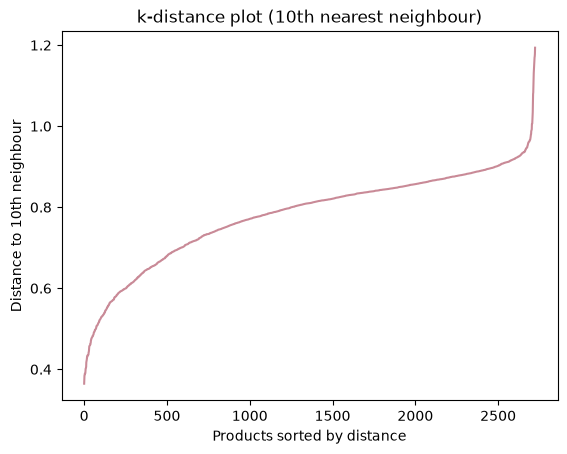

Median distance to 10th neighbour: 0.81


In [15]:
# k-distance plot: the distance from each product to its 10th nearest neighbour, sorted.
# A sharp bend would suggest a good eps; a smooth curve means there are no clearly separated dense regions.
import numpy as np
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

distances, _ = NearestNeighbors(n_neighbors=10).fit(X_lsa).kneighbors(X_lsa)
k_dist = np.sort(distances[:, -1])
plt.plot(k_dist, color="#C98A97")
plt.title("k-distance plot (10th nearest neighbour)")
plt.xlabel("Products sorted by distance")
plt.ylabel("Distance to 10th neighbour")
plt.show()
print("Median distance to 10th neighbour:", round(np.median(k_dist), 3))

In [16]:
# Hyperparameter tuning: try different eps and min_samples values.
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

dbscan_results = []
for min_samples in [5, 10, 20]:
    for eps in [0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_lsa)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise = (labels == -1).mean()
        clustered = labels != -1
        sil = silhouette_score(X_lsa[clustered], labels[clustered]) if n_clusters > 1 else np.nan
        dbscan_results.append({"eps": eps, "min_samples": min_samples, "Clusters": n_clusters,
                               "Noise %": round(noise * 100, 1), "Silhouette (non-noise)": round(sil, 3),
                               "Largest cluster": int(np.bincount(labels[clustered]).max()) if clustered.any() else 0})
dbscan_results = pd.DataFrame(dbscan_results)
display(dbscan_results)

,eps,min_samples,Clusters,Noise %,Silhouette (non-noise),Largest cluster
0,0.55,5,46,78.3,0.398,52
1,0.60,5,58,68.1,0.307,93
2,0.65,5,64,58.2,0.247,122
3,0.70,5,55,43.6,0.093,437
4,0.75,5,22,26.0,-0.080,1742
5,0.80,5,4,9.3,-0.030,2447
6,0.85,5,1,2.2,NaN,2663
7,0.55,10,14,89.2,0.493,52
8,0.60,10,24,81.8,0.416,58
9,0.65,10,27,72.8,0.363,98


In [17]:
# Choose the setting with the highest silhouette score among those that cluster at least half of the products
# (settings that call most products 'noise' are not useful for grouping products).
usable = dbscan_results[(dbscan_results["Noise %"] <= 50) & (dbscan_results["Clusters"] > 1)]
best_db = usable.sort_values("Silhouette (non-noise)", ascending=False).iloc[0]
print("Selected DBSCAN setting:")
print(best_db)

dbscan = DBSCAN(eps=best_db["eps"], min_samples=int(best_db["min_samples"]))
dbscan_labels = dbscan.fit_predict(X_lsa)
df["DBSCAN_Cluster"] = dbscan_labels
print("\nProducts per DBSCAN cluster (-1 = noise):")
print(pd.Series(dbscan_labels).value_counts().head(10))

Selected DBSCAN setting:
eps                         0.750
min_samples                10.000
Clusters                   27.000
Noise %                    46.000
Silhouette (non-noise)      0.098
Largest cluster           597.000
Name: 11, dtype: float64

Products per DBSCAN cluster (-1 = noise):
-1     1254
 6      597
 5      161
 10      68
 3       65
 19      65
 21      48
 1       45
 18      40
 9       39
Name: count, dtype: int64


In [18]:
# What do the largest DBSCAN clusters contain?
for c in pd.Series(dbscan_labels[dbscan_labels != -1]).value_counts().index[:6]:
    members = df[df["DBSCAN_Cluster"] == c]
    print(f"Cluster {c} ({len(members)} products) | categories: {members['category'].value_counts().head(2).to_dict()}"
          f" | brands: {members['brand'].value_counts().head(3).to_dict()}")

Cluster 6 (597 products) | categories: {'Moisturizer': 157, 'Sun protection': 101} | brands: {'Shiseido': 79, 'Clinique': 76, 'Origins': 60}
Cluster 5 (161 products) | categories: {'Treatment': 53, 'Cleanser': 34} | brands: {'Tata Harper': 29, 'REN Clean Skincare': 13, 'Caudalie': 9}
Cluster 10 (68 products) | categories: {'Moisturizer': 25, 'Eye care': 19} | brands: {'fresh': 19, 'Dior': 15, 'Clarins': 11}
Cluster 3 (65 products) | categories: {'Moisturizer': 27, 'Cleanser': 19} | brands: {'CeraVe': 38, 'Drunk Elephant': 5, 'Skinfix': 5}
Cluster 19 (65 products) | categories: {'Treatment': 21, 'Moisturizer': 11} | brands: {'Sk-Ii': 22, 'Mario Badescu': 13, 'Peter Thomas Roth': 6}
Cluster 21 (48 products) | categories: {'Treatment': 11, 'Serum': 8} | brands: {'Murad': 43, 'fresh': 1, 'Lancer': 1}


### Visualising the clusters
The 50 SVD components are projected to 2 dimensions with PCA, so each product becomes a point.
The third plot colours products by their **actual category** for comparison.

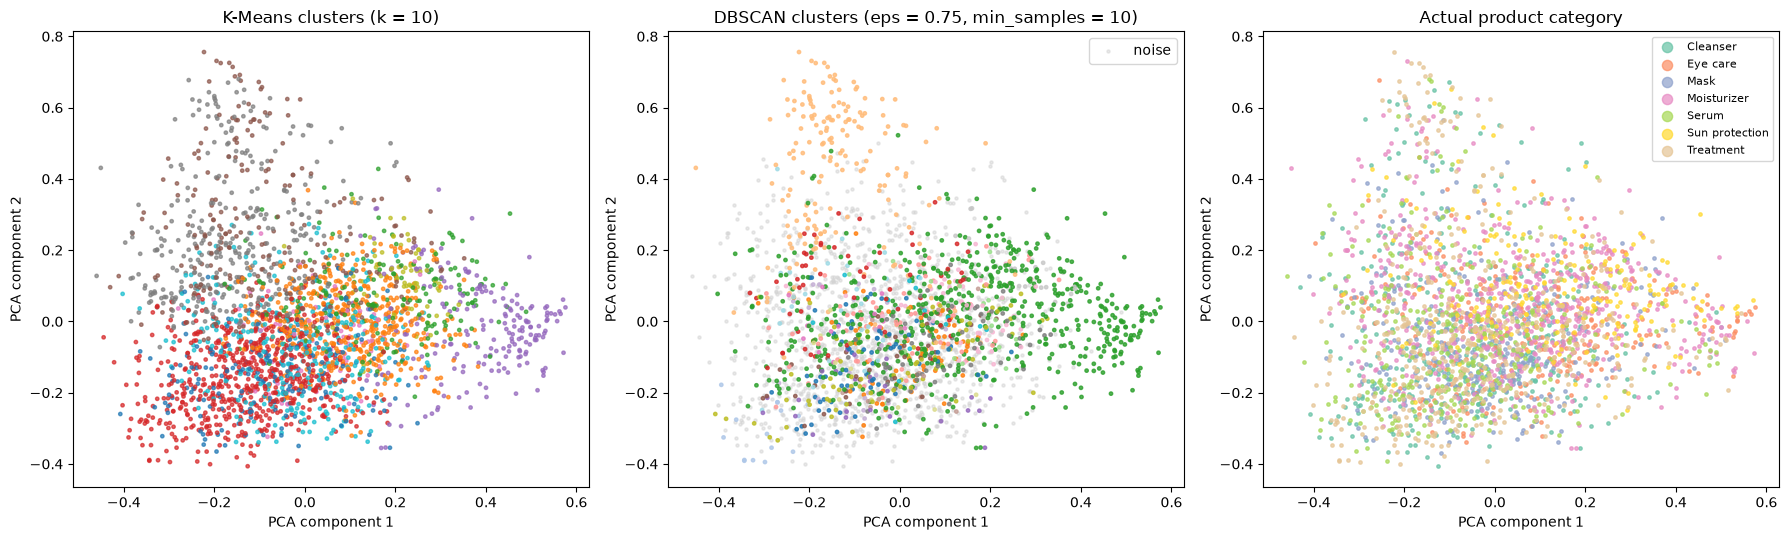

In [19]:
from sklearn.decomposition import PCA
xy = PCA(n_components=2, random_state=42).fit_transform(X_lsa)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
axes[0].scatter(xy[:, 0], xy[:, 1], c=cluster_labels, cmap="tab10", s=6, alpha=0.7)
axes[0].set_title("K-Means clusters (k = 10)")

noise = dbscan_labels == -1
axes[1].scatter(xy[noise, 0], xy[noise, 1], c="lightgray", s=5, alpha=0.5, label="noise")
axes[1].scatter(xy[~noise, 0], xy[~noise, 1], c=dbscan_labels[~noise], cmap="tab20", s=6, alpha=0.8)
axes[1].set_title(f"DBSCAN clusters (eps = {best_db['eps']}, min_samples = {int(best_db['min_samples'])})")
axes[1].legend(loc="upper right")

for i, cat in enumerate(sorted(df["category"].unique())):
    m = (df["category"] == cat).values
    axes[2].scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.7, label=cat, color=plt.cm.Set2(i))
axes[2].set_title("Actual product category")
axes[2].legend(markerscale=3, fontsize=8)
for ax in axes:
    ax.set_xlabel("PCA component 1")
    ax.set_ylabel("PCA component 2")
plt.tight_layout()
plt.show()

### Comparing clusters to actual labels
- **ARI** (Adjusted Rand Index): 1 = clusters match the labels perfectly, 0 = no better than random.
- **NMI** (Normalized Mutual Information): 0 = no shared information, 1 = identical grouping.

Clusters are compared with two real labels: **product category** and **brand**.

In [20]:
import time, pickle

def time_fit(model):
    start = time.perf_counter()
    labels = model.fit_predict(X_lsa)
    return labels, time.perf_counter() - start

km_labels, km_time = time_fit(KMeans(n_clusters=10, random_state=42, n_init=10))
db_labels, db_time = time_fit(DBSCAN(eps=best_db["eps"], min_samples=int(best_db["min_samples"])))

rows = []
for name, labels, seconds, model in [("K-Means", km_labels, km_time, final_kmeans),
                                     ("DBSCAN", db_labels, db_time, dbscan)]:
    clustered = labels != -1
    rows.append({
        "Algorithm": name,
        "Clusters": len(set(labels[clustered])),
        "Noise %": round((~clustered).mean() * 100, 1),
        "Silhouette": round(silhouette_score(X_lsa[clustered], labels[clustered]), 3),
        "ARI vs category": round(adjusted_rand_score(df["category"], labels), 3),
        "NMI vs category": round(normalized_mutual_info_score(df["category"], labels), 3),
        "NMI vs brand": round(normalized_mutual_info_score(df["brand"], labels), 3),
        "Training time (s)": round(seconds, 3),
        "Model size (KB)": round(len(pickle.dumps(model)) / 1024, 1),
    })
cluster_comparison = pd.DataFrame(rows)
display(cluster_comparison)
cluster_comparison.to_csv("clustering_comparison.csv", index=False)

,Algorithm,Clusters,Noise %,Silhouette,ARI vs category,NMI vs category,NMI vs brand,Training time (s),Model size (KB)
0,K-Means,10,0.0,0.067,0.074,0.129,0.296,0.313,15.1
1,DBSCAN,27,46.0,0.098,0.003,0.070,0.371,0.061,360.5


In [21]:
# Save the clustered dataset again, now including the DBSCAN cluster numbers.
df.to_csv("skincare_clustered.csv", index=False)
joblib.dump(dbscan, "dbscan_skinmatch.pkl")
print("Saved skincare_clustered.csv with K-Means and DBSCAN clusters, and dbscan_skinmatch.pkl")

Saved skincare_clustered.csv with K-Means and DBSCAN clusters, and dbscan_skinmatch.pkl


### Conclusion

In this phase, two clustering algorithms, **K-Means** and **DBSCAN**, were applied to 2,724 skincare products.

**Feature representation.** Three representations were tested for K-Means: 11 basic ingredient indicators,
raw TF-IDF (7,316 features) and TF-IDF reduced to 50 components with TruncatedSVD. Raw TF-IDF gave silhouette
scores of about 0.01 because of its very high number of sparse dimensions. Since silhouette scores from different
feature spaces are not directly comparable, the clusters were also judged by their contents: TF-IDF + SVD formed
recognisable product groups (for example sunscreens and foaming cleansers), while basic-feature clusters mixed
product types. TF-IDF + SVD was used for both algorithms.

**K-Means** (k = 10, chosen with the elbow method and cluster interpretability) divides every product into a
group. Its clusters partly follow product type, which is reflected in a higher ARI/NMI with category than DBSCAN.

**DBSCAN** was tuned over `eps` and `min_samples` using a k-distance plot and a grid search. The data has no
clearly separated dense regions: small `eps` values marked almost all products as noise, and large values merged
almost everything into one cluster. With the selected setting, about half of the products are noise and one large
cluster dominates. The smaller DBSCAN clusters mostly contain **products from the same brand** (for example CeraVe
or Murad), because brands reuse similar base formulas. This shows in its NMI with brand being higher than with
category.

**Comparison** (see the table above): K-Means gives more balanced, interpretable groups that match product
categories better and assigns every product to a cluster, which is required for using clusters in the
recommender. DBSCAN's silhouette score is computed only on non-noise products, so it is not directly comparable.
Both algorithms train in well under a second.

**K-Means was therefore selected.** Both algorithms show low silhouette scores, meaning skincare products
overlap heavily in their ingredients. The clusters are used for ingredient-based analysis and as a small
tie-breaker in recommendations, not as predictions of skin-type suitability.